In [2]:
%matplotlib widget
import hyperspy.api as hs
import h5py
import glob
import os
import mrcfile
import numpy as np
from oneview_insitu import load_oneview_insitu, read_root_metadata
import gc
from PIL import Image
from pathlib import Path


In [3]:
# This should be the folder level where multiple or one OneView_IS file is saved
base_dir = '/dls/e02/data/2026/mg45922-1/raw/Au_Ni_Graphene/'
sample_name = base_dir.split('/')[-2]

# Where to write the outcome... Same folder names will be created
output_base = '/dls/e02/data/2026/mg45922-1/processing'

# bin value to save the smaller version of the data
bin_val = 4

In [5]:
sample_name

'Au_Ni_Graphene'

In [6]:
# Find the root_files
data_sets = sorted(glob.glob(base_dir + '/*/Hour_00'))

data_names = [_s.split('/')[-2] for _s in data_sets]
pointer_files = [os.path.join(base_dir, _name, f'{_name}.dm4') for _name in data_names]

In [7]:
data_sets

['/dls/e02/data/2026/mg45922-1/raw/Au_Ni_Graphene/Overview1/Hour_00',
 '/dls/e02/data/2026/mg45922-1/raw/Au_Ni_Graphene/Overview10/Hour_00',
 '/dls/e02/data/2026/mg45922-1/raw/Au_Ni_Graphene/Overview11/Hour_00',
 '/dls/e02/data/2026/mg45922-1/raw/Au_Ni_Graphene/Overview12/Hour_00',
 '/dls/e02/data/2026/mg45922-1/raw/Au_Ni_Graphene/Overview13/Hour_00',
 '/dls/e02/data/2026/mg45922-1/raw/Au_Ni_Graphene/Overview14/Hour_00',
 '/dls/e02/data/2026/mg45922-1/raw/Au_Ni_Graphene/Overview15/Hour_00',
 '/dls/e02/data/2026/mg45922-1/raw/Au_Ni_Graphene/Overview16/Hour_00',
 '/dls/e02/data/2026/mg45922-1/raw/Au_Ni_Graphene/Overview17/Hour_00',
 '/dls/e02/data/2026/mg45922-1/raw/Au_Ni_Graphene/Overview18/Hour_00',
 '/dls/e02/data/2026/mg45922-1/raw/Au_Ni_Graphene/Overview19/Hour_00',
 '/dls/e02/data/2026/mg45922-1/raw/Au_Ni_Graphene/Overview2/Hour_00',
 '/dls/e02/data/2026/mg45922-1/raw/Au_Ni_Graphene/Overview20/Hour_00',
 '/dls/e02/data/2026/mg45922-1/raw/Au_Ni_Graphene/Overview21/Hour_00',
 '/dls/e

### Batch processing

Iterating over the datasets

In [8]:
from oneview_insitu import load_oneview_insitu, blockwise_mean, raise_open_file_limit

raise_open_file_limit()      # once per kernel, before any lazy loading
block_size = 50

for i, _d_path in enumerate(pointer_files):
    save_path = os.path.join(output_base, sample_name, data_names[i])
    done_marker = os.path.join(save_path, '.complete')

    # Skip only datasets that actually finished, not ones that crashed midway
    if os.path.exists(done_marker):
        print(f'skipping {data_names[i]} (already complete)')
        continue
    os.makedirs(save_path, exist_ok=True)

    s = None
    data_bin = None
    try:
        s = load_oneview_insitu(_d_path)

        # Blockwise: keeps at most block_size frames (and memmaps) open at once
        mean_image = blockwise_mean(s, block_size=block_size)
        im = mean_image.data
        vmin, vmax = np.percentile(im, (0.5, 99.5))
        im8 = (255 * np.clip((im - vmin) / (vmax - vmin), 0, 1)).astype(np.uint8)
        Image.fromarray(im8).save(os.path.join(save_path, 'mean_image.png'))
        mean_image.save(os.path.join(save_path, 'mean_image.hspy'), overwrite=True)

        # Full-resolution stack
        s.save(save_path + f'/{data_names[i]}_full_stack.hspy',
               chunks=(20,) + s.data.shape[1:], overwrite=True)

        # Binned MRC movie
        data_bin = s.rebin(scale=(1, bin_val, bin_val))
        data = data_bin.data
        nframes, ny, nx = data.shape
        outfile = save_path + f'/{data_names[i]}_bin{bin_val}.mrc'

        with mrcfile.new_mmap(outfile, shape=(nframes, ny, nx),
                              mrc_mode=2, overwrite=True) as mrc:
            for start in range(0, nframes, block_size):
                stop = min(start + block_size, nframes)
                mrc.data[start:stop] = data[start:stop].compute().astype(np.float32)
                gc.collect()          # release this block's memmaps
                print(f'\r{stop}/{nframes} frames written', end='')

            px = data_bin.axes_manager.signal_axes[0].scale
            units = data_bin.axes_manager.signal_axes[0].units
            if units.lower() in ['nm', 'nanometer', 'nanometre']:
                mrc.voxel_size = (px, px, 1.0)

        Path(done_marker).touch()
        print(f'\nFinished with {data_names[i]}')

    except Exception as err:
        # One bad dataset should not kill the whole batch
        print(f'\nFAILED {data_names[i]}: {type(err).__name__}: {err}')

    finally:
        del s, data_bin
        gc.collect()

open-file limit raised 4096 -> 262144 (hard 262144)
Found 952 frames under /dls/e02/data/2026/mg45922-1/raw/Au_Ni_Graphene/Overview1


/tmp/ipykernel_211701/2247779697.py:19: UserWarning: 2 of 36 interior Second_* folders do not hold 25 frames (e.g. Second_15: 26). The uniform time axis will drift where frames were dropped.
  s = load_oneview_insitu(_d_path)


WARNING | Hyperspy | Axis calibration mismatch detected along axis 0. The calibration of signal 0 along this axis will be applied to all signals after stacking. (hyperspy.misc._signal_tools:110)
WARNING | Hyperspy | Axis calibration mismatch detected along axis 1. The calibration of signal 0 along this axis will be applied to all signals after stacking. (hyperspy.misc._signal_tools:110)

<LazySignal2D, title: Overview1, dimensions: (952|4096, 4096)>
  time      : 952 frames @ 25.0637144685505 fps (37.98 s)
  pixel size: 0.0126196 nm
  beam      : 60 kV, mag 1e+06x
  camera    : OneView, exposure 0.039898316 s, binning 1
  in-situ   : Heating:Wildfire Holder:Temperature, Heating:Wildfire Holder:Temperature Setpoint, Heating:Wildfire Holder:Power
  mean: 952/952 frames
[########################################] | 100% Completed | 26m 7sss
952/952 frames written
Finished with Overview1
Found 3396 frames under /dls/e02/data/2026/mg45922-1/raw/Au_Ni_Graphene/Overview10
WARNING | Hyperspy | 

/tmp/ipykernel_211701/2247779697.py:19: UserWarning: 32 of 83 interior Second_* folders do not hold 100 frames (e.g. Second_02: 101). The uniform time axis will drift where frames were dropped.
  s = load_oneview_insitu(_d_path)


WARNING | Hyperspy | Axis calibration mismatch detected along axis 0. The calibration of signal 0 along this axis will be applied to all signals after stacking. (hyperspy.misc._signal_tools:110)
WARNING | Hyperspy | Axis calibration mismatch detected along axis 1. The calibration of signal 0 along this axis will be applied to all signals after stacking. (hyperspy.misc._signal_tools:110)

<LazySignal2D, title: Overview17, dimensions: (8519|2048, 2048)>
  time      : 8519 frames @ 100.38677014802632 fps (84.86 s)
  pixel size: 0.0126196 nm
  beam      : 60 kV, mag 2e+06x
  camera    : OneView, exposure 0.009961472 s, binning 2
  in-situ   : Heating:Wildfire Holder:Temperature, Heating:Wildfire Holder:Temperature Setpoint, Heating:Wildfire Holder:Power
  mean: 8519/8519 frames
[########################################] | 100% Completed | 57m 44s
8519/8519 frames written
Finished with Overview17
Found 5112 frames under /dls/e02/data/2026/mg45922-1/raw/Au_Ni_Graphene/Overview18
WARNING | Hy

...

WARNING | Hyperspy | Axis calibration mismatch detected along axis 0. The calibration of signal 0 along this axis will be applied to all signals after stacking. (hyperspy.misc._signal_tools:110)
WARNING | Hyperspy | Axis calibration mismatch detected along axis 1. The calibration of signal 0 along this axis will be applied to all signals after stacking. (hyperspy.misc._signal_tools:110)

<LazySignal2D, title: Overview3, dimensions: (12934|4096, 4096)>
  time      : 12934 frames @ 25.0637144685505 fps (516.04 s)
  pixel size: 0.00630982 nm
  beam      : 60 kV, mag 2e+06x
  camera    : OneView, exposure 0.039898316 s, binning 1
  in-situ   : Heating:Wildfire Holder:Temperature, Heating:Wildfire Holder:Temperature Setpoint, Heating:Wildfire Holder:Power
  mean: 12934/12934 frames
[########################################] | 100% Completed | 5hr 59m
12934/12934 frames written
Finished with Overview3
Found 8221 frames under /dls/e02/data/2026/mg45922-1/raw/Au_Ni_Graphene/Overview4


/tmp/ipykernel_211701/2247779697.py:19: UserWarning: 20 of 326 interior Second_* folders do not hold 25 frames (e.g. Second_15: 26). The uniform time axis will drift where frames were dropped.
  s = load_oneview_insitu(_d_path)


WARNING | Hyperspy | Axis calibration mismatch detected along axis 0. The calibration of signal 0 along this axis will be applied to all signals after stacking. (hyperspy.misc._signal_tools:110)
WARNING | Hyperspy | Axis calibration mismatch detected along axis 1. The calibration of signal 0 along this axis will be applied to all signals after stacking. (hyperspy.misc._signal_tools:110)

<LazySignal2D, title: Overview4, dimensions: (8221|4096, 4096)>
  time      : 8221 frames @ 25.0637144685505 fps (328.00 s)
  pixel size: 0.00630982 nm
  beam      : 60 kV, mag 2e+06x
  camera    : OneView, exposure 0.039898316 s, binning 1
  in-situ   : Heating:Wildfire Holder:Temperature, Heating:Wildfire Holder:Temperature Setpoint, Heating:Wildfire Holder:Power
  mean: 8221/8221 frames
[########################################] | 100% Completed | 3hr 56m
8221/8221 frames written
Finished with Overview4
Found 11522 frames under /dls/e02/data/2026/mg45922-1/raw/Au_Ni_Graphene/Overview5


/tmp/ipykernel_211701/2247779697.py:19: UserWarning: 44 of 113 interior Second_* folders do not hold 100 frames (e.g. Second_02: 101). The uniform time axis will drift where frames were dropped.
  s = load_oneview_insitu(_d_path)


WARNING | Hyperspy | Axis calibration mismatch detected along axis 0. The calibration of signal 0 along this axis will be applied to all signals after stacking. (hyperspy.misc._signal_tools:110)
WARNING | Hyperspy | Axis calibration mismatch detected along axis 1. The calibration of signal 0 along this axis will be applied to all signals after stacking. (hyperspy.misc._signal_tools:110)

<LazySignal2D, title: Overview5, dimensions: (11522|2048, 2048)>
  time      : 11522 frames @ 100.38677014802632 fps (114.78 s)
  pixel size: 0.0168262 nm
  beam      : 60 kV, mag 1.5e+06x
  camera    : OneView, exposure 0.009961472 s, binning 2
  in-situ   : Heating:Wildfire Holder:Temperature, Heating:Wildfire Holder:Temperature Setpoint, Heating:Wildfire Holder:Power
  mean: 11522/11522 frames
[########################################] | 100% Completed | 80m 49s
11522/11522 frames written
Finished with Overview5
Found 70027 frames under /dls/e02/data/2026/mg45922-1/raw/Au_Ni_Graphene/Overview6
WARNI

## Lazy loading of the full in-situ movie - TESTING on ONE Dataset

The per-frame `.dm4` files carry no calibration - all of it lives in the single
root file (`Overview28.dm4`) written next to the `Hour_*` folders. `load_oneview_insitu`
stacks the frames lazily and transplants the root file's calibration and metadata
onto the stack.

Requires `oneview_insitu.py` to sit next to this notebook.

In [10]:
from oneview_insitu import load_oneview_insitu, read_root_metadata

root_file = '/dls/e02/data/2026/mg45922-1/raw/AuNi_SWCNT/Overview28/Overview28.dm4'

s = load_oneview_insitu(root_file)
s

Found 3079 frames under /dls/e02/data/2026/mg45922-1/raw/AuNi_SWCNT/Overview28
WARNING | Hyperspy | Axis calibration mismatch detected along axis 0. The calibration of signal 0 along this axis will be applied to all signals after stacking. (hyperspy.misc._signal_tools:110)
WARNING | Hyperspy | Axis calibration mismatch detected along axis 1. The calibration of signal 0 along this axis will be applied to all signals after stacking. (hyperspy.misc._signal_tools:110)

<LazySignal2D, title: Overview28, dimensions: (3079|2048, 2048)>
  time      : 3079 frames @ 20.0 fps (153.95 s)
  pixel size: 0.0126196 nm
  beam      : 60 kV, mag 2e+06x
  camera    : OneView, exposure 0.05 s, binning 2
  in-situ   : Heating:Wildfire Holder:Temperature, Heating:Wildfire Holder:Temperature Setpoint, Heating:Wildfire Holder:Power


<LazySignal2D, title: Overview28, dimensions: (3079|2048, 2048)>

In [11]:
# Calibrated time (navigation) and real-space (signal) axes
s.axes_manager

Navigation axis name,size,index,offset,scale,units
time,3079,0,0.0,0.05,s
Signal axis name,size,,offset,scale,units
x,2048,,-0.0,0.012619645334780216,nm
y,2048,,-0.0,0.012619645334780216,nm


In [12]:
# Metadata mapped from the root file's DM tags
s.metadata

├── Acquisition_instrument
│   └── TEM
│       ├── Camera
│       │   └── exposure = 0.05
│       ├── Detector
│       │   └── Camera
│       │       ├── binning = 2
│       │       ├── exposure = 0.05
│       │       ├── frame_rate = 20.0
│       │       ├── id = OneView-42204590024
│       │       ├── name = OneView
│       │       └── temperature = -5.0234375
│       ├── In_situ
│       │   ├── counts_to_electrons = 0.03336961194872856
│       │   ├── duration_s = 153.95
│       │   ├── experiment_start = 2026-07-02 17:00:37.312
│       │   ├── frame_rate_fps = 20.0
│       │   ├── logged_channels <list>
│       │   │   ╠══ [0]
│       │   │   ║   ╠══ name = Wildfire Holder
│       │   │   ║   ╠══ path = Heating:Wildfire Holder:Temperature
│       │   │   ║   ╚══ units = °C
│       │   │   ╠══ [1]
│       │   │   ║   ╠══ name = Wildfire Holder
│       │   │   ║   ╠══ path = Heating:Wildfire Holder:Temperature Setpoint
│       │   │   ║   ╚══ units = °C
│       │   │   ╚══ [2]
│       │   │       ╠══ name = Wildfire Holder
│       │   │       ╠══ path = Heating:Wildfire Holder:Power
│       │   │       ╚══ units = mW
│       │   ├── n_frames_expected = 3079
│       │   └── n_frames_loaded = 3079
│       ├── Stage
│       │   ├── tilt_alpha = 0.0500000007450581
│       │   ├── tilt_beta = 0.0
│       │   ├── x = -0.12261839843750001
│       │   ├── y = 0.080909703125
│       │   └── z = -0.0244200019836426
│       ├── acquisition_mode = TEM
│       ├── actual_magnification = 2377245.8895749524
│       ├── beam_current = 0.0
│       ├── beam_energy = 60.0
│       ├── magnification = 2000000.0
│       └── microscope = ARM300CF
├── General
│   ├── FileIO
│   │   └── 0
│   │       ├── hyperspy_version = 2.4.0
│   │       ├── io_plugin = rsciio.digitalmicrograph
│   │       ├── operation = load
│   │       └── timestamp = 2026-07-30T09:44:09.729588+00:00
│   ├── date = 2026-07-02
│   ├── original_filename = Overview28.dm4
│   ├── time = 17:00:37.312
│   └── title = Overview28
└── Signal
    ├── Noise_properties
    │   └── Variance_linear_model
    │       ├── gain_factor = 0.03336961194872856
    │       └── gain_offset = 0.0
    ├── quantity = Electrons (Counts)
    └── signal_type =

In [13]:
# The complete root tag tree is preserved as well
s.original_metadata.ImageList.TagGroup0.ImageTags['In-situ']

├── Raw File Format Info
│   ├── Calibrations
│   │   ├── dim-0
│   │   │   ├── Origin = -0.0
│   │   │   ├── Scale = 0.012619645334780216
│   │   │   └── Unit = nm
│   │   ├── dim-1
│   │   │   ├── Origin = -0.0
│   │   │   ├── Scale = 0.012619645334780216
│   │   │   └── Unit = nm
│   │   └── intensity
│   │       ├── Origin = 0.0
│   │       ├── Scale = 0.03336961194872856
│   │       └── Unit = e-
│   ├── Data Size (bytes) = 4
│   ├── Data Type = 2
│   ├── Dimensions
│   │   ├── Data0 = 2048
│   │   └── Data1 = 2048
│   ├── Frame Size (bytes) = 16777216
│   └── Stored per second = 0
└── Recorded
    ├── Duration (s) = 153.95
    ├── Experiment Start Time = 2026-07-02 17:00:37.312
    ├── # Frames = 3079
    └── Sync
        ├── Experiment Start (System-clock tick) = 17830116373121213
        └── Linear
            ├── First Frame Time (ns) = 0
            └── Frame Rate (fps) = 20.0

### Working with the lazy stack

Only the frames you touch are read from disk. Call `.compute()` on reduced
results, never on the whole stack.

In [ ]:
s.plot()                     # reads one frame at a time

  0%|          | 0/7186 [00:00<?, ?it/s]

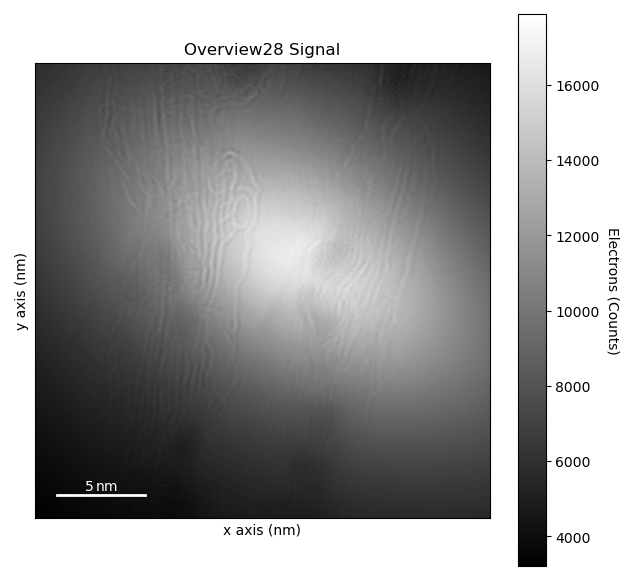

In [13]:
mean_image = s.mean(axis='time')
mean_image.compute()
mean_image.plot()

### Convert once for fast re-analysis

Re-loading thousands of `.dm4` files is slow (every header is re-read). Save the
assembled stack to a chunked container once; subsequent loads are near-instant.

`.zspy` is unavailable in this environment (rosettasciio 0.9.0 predates zarr 3.x),
so use `.hspy` (HDF5). Note HDF5 needs explicit chunk sizes - the `-1` shorthand
is a dask/zarr convention and raises `OverflowError` here.

In [14]:
# ~1 s of frames per chunk, whole frame per chunk in x/y
output_path = '/dls/e02/data/2026/mg45922-1/processing'
s.save(output_path + '/Overview28_stack.hspy', chunks=(20,) + s.data.shape[1:])

# later:
# import hyperspy.api as hs
# s = hs.load('Overview28_stack.hspy', lazy=True)

[########################################] | 100% Completed | 21m 20s


### Export to video

Writing to MRC file

In [20]:
output_path = '/dls/e02/data/2026/mg45922-1/processing'
bin_val = 4
data_bin = s.rebin(scale=(1, bin_val, bin_val))       # 2048 -> 512 px, lazy; drop this line for full res

data = data_bin.data
nframes, ny, nx = data.shape

outfile = output_path + f'/Overview28_bin{bin_val}.mrc'

with mrcfile.new_mmap(
        outfile,
        shape=(nframes, ny, nx),
        mrc_mode=2,          # float32
        overwrite=True) as mrc:

    block_size = 50

    for start in range(0, nframes, block_size):
        stop = min(start + block_size, nframes)

        block = data[start:stop].compute().astype(np.float32)

        mrc.data[start:stop] = block

        print(f"\r{stop}/{nframes} frames written", end="")

    # pixel size metadata
    px = data_bin.axes_manager.signal_axes[0].scale
    units = data_bin.axes_manager.signal_axes[0].units

    if units.lower() in ['nm', 'nanometer', 'nanometre']:
        mrc.voxel_size = (px, px, 1.0)

print("\nFinished")

3079/3079 frames written
Finished


In [21]:
test = hs.load(output_path + f'/Overview28_bin{bin_val}.mrc')

In [22]:
test

<Signal2D, title: , dimensions: (3079|512, 512)>

In [24]:
test.axes_manager

Navigation axis name,size,index,offset,scale,units
z,3079,0,0.0,0.1,
Signal axis name,size,,offset,scale,units
x,512,,0.0,0.005047858133912087,nm
y,512,,0.0,0.005047858133912087,nm


In [25]:
test.plot()